# Diyabetik Hastalarda 30 Gün İçinde Yeniden Hastaneye Yatışın Tahmini
**Yapay Sinir Ağları F26 – Dönem Ödevi**

Veri seti: *Diabetes 130-US Hospitals for Years 1999–2008* (UCI ML Repository, id 296) – Strack vd. (2014), https://doi.org/10.24432/C5230J

Problem: Bir diyabet hastasının taburcu olduktan sonra **30 gün içinde** tekrar hastaneye yatıp yatmayacağını tahmin etmek (ikili, dengesiz sınıflandırma; pozitif oran ≈ %11).

Modeller: Lojistik Regresyon, k-En Yakın Komşu, Gaussian Naive Bayes, Random Forest, XGBoost ve iki yapay sinir ağı: Çok Katmanlı Algılayıcı (MLP, scikit-learn) ve embedding katmanlı derin ağ (Keras).

Aynı hasta veri setinde birden fazla kez bulunduğu için bölme **hasta bazında** yapılıyor (bir hastanın tüm yatışları ya train'de, ya validation'da ya da test'te). Tüm ön işleme `Pipeline` içinde ve yalnızca eğitim verisiyle fit ediliyor.
**Revision note:** Only written interpretations and the finite-bootstrap p-value reporting were updated after the saved Kaggle run. Original predictions, model metrics, sample splits and figure data are unchanged. Re-running the notebook will regenerate corrected p-values.


In [1]:
import io
import os
import time
import zipfile
import urllib.request
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, randint, uniform

from sklearn.model_selection import (StratifiedGroupKFold, GroupShuffleSplit, train_test_split, ParameterGrid,
                                     ParameterSampler)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, roc_curve, precision_recall_curve, log_loss)
from xgboost import XGBClassifier
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "imbalanced-learn"])
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
import tensorflow as tf
import keras
from keras import layers

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)
tf.config.set_visible_devices([], "GPU")         # deterministik modda bazı GPU işlemleri hata verebiliyor
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()   # keras sonuçları her çalıştırmada aynı çıksın
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"LR": "#7F8C8D", "kNN": "#B7950B", "NB": "#8E44AD", "RF": "#27AE60", "XGB": "#C0392B", "MLP": "#2E86C1",
          "ANN2": "#17202A"}
NAMES = {"LR": "Logistic Regression", "kNN": "k-NN", "NB": "Gaussian NB",
         "RF": "Random Forest", "XGB": "XGBoost", "MLP": "MLP (ANN)", "ANN2": "Embedding ANN (Keras)"}


def save_fig(name):
    # makale için 600 dpi
    plt.savefig(f"figures/{name}.png", dpi=600, bbox_inches="tight")
    plt.show()

## 1. Veri setinin yüklenmesi

In [2]:
URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
raw = urllib.request.urlopen(URL).read()
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    # dikkat: veride "None" = test yapılmadı demek, pandas bunu varsayılan olarak NaN yapıyor.
    # o yüzden sadece "?" eksik değer olarak okunuyor
    df_raw = pd.read_csv(z.open("diabetic_data.csv"), keep_default_na=False, na_values=["?"], low_memory=False)

print(df_raw.shape)
print("Hasta sayısı:", df_raw["patient_nbr"].nunique())
df_raw.head()

(101766, 50)
Hasta sayısı: 71518


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
miss = (df_raw.isna().mean() * 100).sort_values(ascending=False)
miss[miss > 0].round(2)

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

In [4]:
print(df_raw["readmitted"].value_counts())
print()
enc_per_patient = df_raw.groupby("patient_nbr").size()
print("Birden fazla yatışı olan hasta:", (enc_per_patient > 1).sum(),
      f"({(enc_per_patient > 1).mean() * 100:.1f}%)")
print("Bir hastanın en fazla yatış sayısı:", enc_per_patient.max())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Birden fazla yatışı olan hasta: 16773 (23.5%)
Bir hastanın en fazla yatış sayısı: 40


## 2. Satır bazlı temizlik ve problem tanımı
Bu adımdaki işlemler her satıra tek başına uygulanan, veriden istatistik öğrenmeyen kurallar olduğu için bölmeden önce yapılabilir:
- Taburculuk şekli **ölüm veya hospis** olan yatışlar çıkarıldı (bu hastalar için yeniden yatış zaten mümkün değil; Strack vd. 2014 ile aynı).
- Cinsiyeti "Unknown/Invalid" olan 3 kayıt çıkarıldı.
- Hedef: `readmitted == "<30"` → 1, diğerleri (`>30`, `NO`) → 0.
- ICD-9 tanı kodları 9 klinik gruba ayrıldı, yaş aralığı orta noktasına çevrildi, ilaç değişikliklerinden sayısal özetler türetildi.

In [5]:
DEATH_HOSPICE = [11, 13, 14, 19, 20, 21]
df = df_raw[~df_raw["discharge_disposition_id"].isin(DEATH_HOSPICE)].copy()
df = df[df["gender"] != "Unknown/Invalid"].copy()
print("Kalan kayıt:", len(df), "| çıkarılan:", len(df_raw) - len(df))

y_all = (df["readmitted"] == "<30").astype(int).values
groups_all = df["patient_nbr"].values
print(f"Pozitif oran (<30 gün): {y_all.mean() * 100:.2f}%")

MEDS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
        "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
        "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
        "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]


def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code[0] in "VE":
        return "Other"
    v = float(code)
    if 390 <= v <= 459 or int(v) == 785:
        return "Circulatory"
    if 460 <= v <= 519 or int(v) == 786:
        return "Respiratory"
    if 520 <= v <= 579 or int(v) == 787:
        return "Digestive"
    if int(v) == 250:
        return "Diabetes"
    if 800 <= v <= 999:
        return "Injury"
    if 710 <= v <= 739:
        return "Musculoskeletal"
    if 580 <= v <= 629 or int(v) == 788:
        return "Genitourinary"
    if 140 <= v <= 239:
        return "Neoplasms"
    return "Other"


def build_features(d):
    X = pd.DataFrame(index=d.index)
    X["age"] = d["age"].str.extract(r"\[(\d+)-").astype(float)[0] + 5
    for c in ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
              "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]:
        X[c] = d[c]
    X["service_use"] = d["number_outpatient"] + d["number_emergency"] + d["number_inpatient"]
    X["n_med_changes"] = d[MEDS].isin(["Up", "Down"]).sum(axis=1)
    X["n_meds_used"] = (d[MEDS] != "No").sum(axis=1)
    for c in ["race", "gender", "payer_code", "medical_specialty", "max_glu_serum", "A1Cresult",
              "change", "diabetesMed"]:
        X[c] = d[c]
    for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
        X[c] = d[c].astype(str)
    for i in (1, 2, 3):
        X[f"diag_{i}"] = d[f"diag_{i}"].map(icd9_group)
    for m in MEDS:
        X["med_" + m] = d[m]
    X["weight"] = d["weight"]
    return X


X_all = build_features(df)
print(X_all.shape)
X_all.head()

Kalan kayıt: 99340 | çıkarılan: 2426
Pozitif oran (<30 gün): 11.39%
(99340, 50)


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,service_use,...,med_tolazamide,med_examide,med_citoglipton,med_insulin,med_glyburide-metformin,med_glipizide-metformin,med_glimepiride-pioglitazone,med_metformin-rosiglitazone,med_metformin-pioglitazone,weight
0,5.0,1,41,0,1,0,0,0,1,0,...,No,No,No,No,No,No,No,No,No,NaN
1,15.0,3,59,0,18,0,0,0,9,0,...,No,No,No,Up,No,No,No,No,No,NaN
2,25.0,2,11,5,13,2,0,1,6,3,...,No,No,No,No,No,No,No,No,No,NaN
3,35.0,2,44,1,16,0,0,0,7,0,...,No,No,No,Up,No,No,No,No,No,NaN
4,45.0,1,51,0,8,0,0,0,5,0,...,No,No,No,Steady,No,No,No,No,No,NaN


## 3. Hasta bazlı Train / Validation / Test ayrımı
`StratifiedGroupKFold` ile hem hasta grupları korunuyor hem de sınıf oranı her bölümde yaklaşık aynı tutuluyor. Önce verinin 1/5'i test, kalanın 1/4'ü validation olarak ayrılıyor → **%60 / %20 / %20**.

In [6]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(sgkf.split(X_all, y_all, groups_all))
sgkf2 = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
tr_rel, va_rel = next(sgkf2.split(X_all.iloc[dev_idx], y_all[dev_idx], groups_all[dev_idx]))
train_idx, val_idx = dev_idx[tr_rel], dev_idx[va_rel]

X_train, y_train, g_train = X_all.iloc[train_idx], y_all[train_idx], groups_all[train_idx]
X_val, y_val, g_val = X_all.iloc[val_idx], y_all[val_idx], groups_all[val_idx]
X_test, y_test, g_test = X_all.iloc[test_idx], y_all[test_idx], groups_all[test_idx]

# hiçbir hasta iki farklı bölümde olmamalı
assert not set(g_train) & set(g_val)
assert not set(g_train) & set(g_test)
assert not set(g_val) & set(g_test)

split_tab = pd.DataFrame({
    "Encounters": [len(y_train), len(y_val), len(y_test)],
    "Patients": [len(set(g_train)), len(set(g_val)), len(set(g_test))],
    "Readmitted <30": [y_train.sum(), y_val.sum(), y_test.sum()],
    "Positive rate (%)": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Validation", "Test"]).round(2)
split_tab.to_csv("results/table_split.csv")
split_tab

,Encounters,Patients,Readmitted <30,Positive rate (%)
Train,59616,42032,6799,11.40
Validation,19693,14004,2196,11.15
Test,20031,13951,2319,11.58


## 4. Keşifsel veri analizi (yalnızca eğitim seti)

In [7]:
tr = X_train.copy()
tr["y"] = y_train

num_desc = tr[["age", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
               "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]].describe().T
num_desc.round(2)

,count,mean,std,min,25%,50%,75%,max
age,59616.0,65.76,15.88,5.0,55.0,65.0,75.0,95.0
time_in_hospital,59616.0,4.40,2.98,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,59616.0,42.89,19.66,1.0,31.0,44.0,57.0,126.0
num_procedures,59616.0,1.33,1.70,0.0,0.0,1.0,2.0,6.0
num_medications,59616.0,15.97,8.07,1.0,10.0,15.0,20.0,81.0
number_outpatient,59616.0,0.37,1.23,0.0,0.0,0.0,0.0,36.0
number_emergency,59616.0,0.19,0.82,0.0,0.0,0.0,0.0,37.0
number_inpatient,59616.0,0.63,1.25,0.0,0.0,0.0,1.0,19.0
number_diagnoses,59616.0,7.41,1.94,1.0,6.0,8.0,9.0,16.0


In [8]:
# eksik oranlarına train üzerinden bakıp karar veriyorum
train_missing = (X_train.isna().mean() * 100).sort_values(ascending=False)
print(train_missing[train_missing > 0].round(2))
DROP_COLS = list(train_missing[train_missing > 90].index)
print("Atılan sütunlar (train'de >%90 eksik):", DROP_COLS)

weight               96.88
medical_specialty    49.06
payer_code           39.77
race                  2.24
dtype: float64
Atılan sütunlar (train'de >%90 eksik): ['weight']


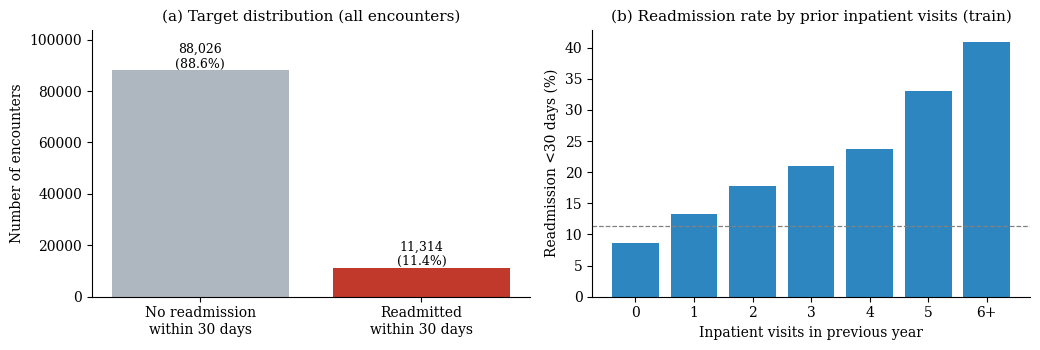

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
cnt = pd.Series(y_all).value_counts().sort_index()
axes[0].bar(["No readmission\nwithin 30 days", "Readmitted\nwithin 30 days"], cnt.values, color=["#AEB6BF", "#C0392B"])
for i, v in enumerate(cnt.values):
    axes[0].text(i, v + 900, f"{v:,}\n({v / cnt.sum() * 100:.1f}%)", ha="center", fontsize=9)
axes[0].set_ylim(0, cnt.max() * 1.18)
axes[0].set_ylabel("Number of encounters")
axes[0].set_title("(a) Target distribution (all encounters)")

inp = tr["number_inpatient"].clip(upper=6)
rate = tr.groupby(inp)["y"].agg(["mean", "size"])
axes[1].bar(rate.index.astype(int).astype(str).str.replace("6", "6+"), rate["mean"] * 100, color="#2E86C1")
axes[1].axhline(y_train.mean() * 100, ls="--", color="grey", lw=0.9)
axes[1].set_xlabel("Inpatient visits in previous year")
axes[1].set_ylabel("Readmission <30 days (%)")
axes[1].set_title("(b) Readmission rate by prior inpatient visits (train)")
plt.tight_layout()
save_fig("fig1_target_and_inpatient")

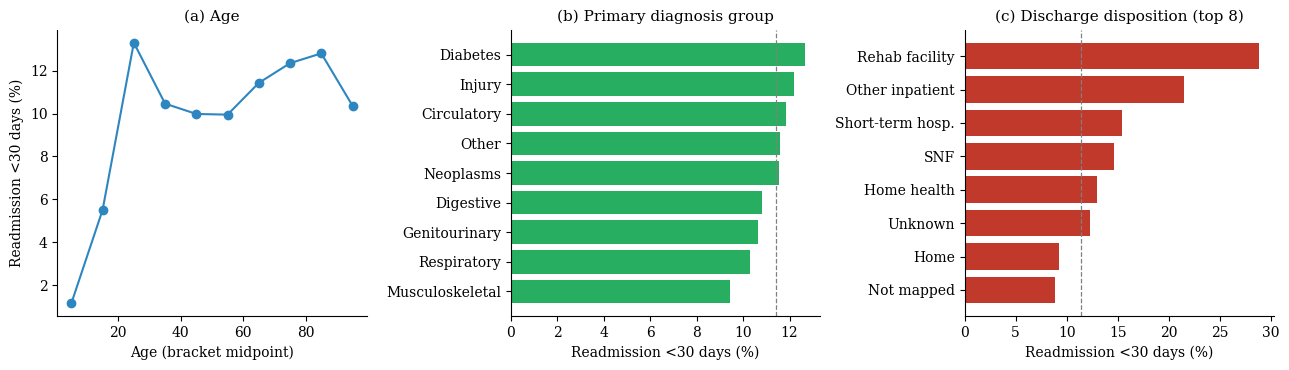

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
age_rate = tr.groupby("age")["y"].mean() * 100
axes[0].plot(age_rate.index, age_rate.values, marker="o", color="#2E86C1")
axes[0].set_xlabel("Age (bracket midpoint)")
axes[0].set_ylabel("Readmission <30 days (%)")
axes[0].set_title("(a) Age")

dg = tr.groupby("diag_1")["y"].agg(["mean", "size"])
dg = dg[dg["size"] >= 100].sort_values("mean")   # 100'den küçük gruplarda oran güvenilir değil
axes[1].barh(dg.index, dg["mean"] * 100, color="#27AE60")
axes[1].axvline(y_train.mean() * 100, ls="--", color="grey", lw=0.9)
axes[1].set_xlabel("Readmission <30 days (%)")
axes[1].set_title("(b) Primary diagnosis group")

top_dd = tr["discharge_disposition_id"].value_counts().head(8).index
dd = tr[tr["discharge_disposition_id"].isin(top_dd)].groupby("discharge_disposition_id")["y"].mean().sort_values() * 100
dd_names = {"1": "Home", "2": "Short-term hosp.", "3": "SNF", "4": "ICF", "5": "Other inpatient",
            "6": "Home health", "18": "Unknown", "22": "Rehab facility", "25": "Not mapped",
            "7": "Left AMA", "23": "Long-term hosp."}
axes[2].barh([dd_names.get(i, i) for i in dd.index], dd.values, color="#C0392B")
axes[2].axvline(y_train.mean() * 100, ls="--", color="grey", lw=0.9)
axes[2].set_xlabel("Readmission <30 days (%)")
axes[2].set_title("(c) Discharge disposition (top 8)")
plt.tight_layout()
save_fig("fig2_eda_rates")

In [11]:
# sayısal değişkenler için Mann-Whitney U ve etki büyüklüğü (rank-biserial), sadece train
rows = []
for c in ["age", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
          "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
          "service_use", "n_med_changes", "n_meds_used"]:
    a, b = tr.loc[tr.y == 1, c], tr.loc[tr.y == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    rows.append((c, a.median(), b.median(), 2 * u / (len(a) * len(b)) - 1, p))
eda_num = pd.DataFrame(rows, columns=["Variable", "Median (readm.)", "Median (not)", "Rank-biserial r", "p"])
eda_num.sort_values("Rank-biserial r", key=abs, ascending=False).round(4)

,Variable,Median (readm.),Median (not),Rank-biserial r,p
7,number_inpatient,0.0,0.0,0.2115,0.0000
9,service_use,1.0,0.0,0.2052,0.0000
1,time_in_hospital,4.0,4.0,0.1020,0.0000
4,num_medications,16.0,15.0,0.0885,0.0000
8,number_diagnoses,9.0,8.0,0.0863,0.0000
6,number_emergency,0.0,0.0,0.0641,0.0000
0,age,65.0,65.0,0.0532,0.0000
10,n_med_changes,0.0,0.0,0.0502,0.0000
2,num_lab_procedures,45.0,44.0,0.0480,0.0000
5,number_outpatient,0.0,0.0,0.0368,0.0000


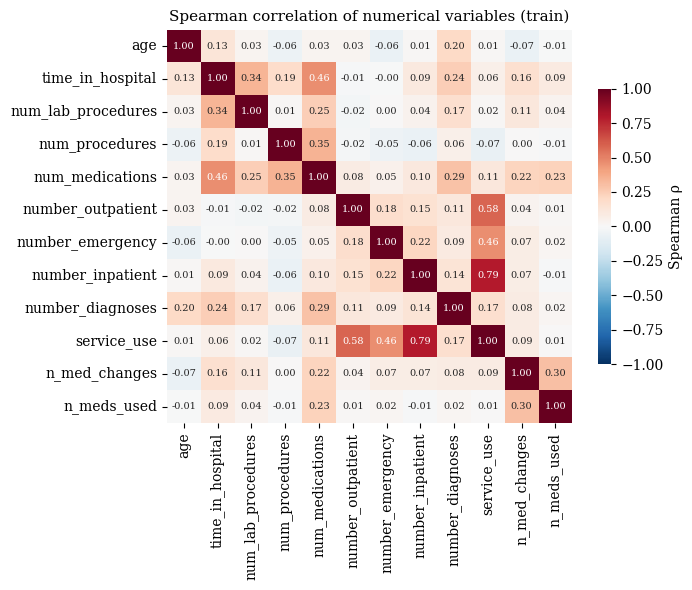

In [12]:
corr = tr[["age", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
           "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
           "service_use", "n_med_changes", "n_meds_used"]].corr(method="spearman")
plt.figure(figsize=(7, 6))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"fontsize": 7},
            cbar_kws={"shrink": 0.7, "label": "Spearman ρ"})
plt.title("Spearman correlation of numerical variables (train)")
plt.tight_layout()
save_fig("figS1_correlation")

Gözlemler:
- Sınıflar çok dengesiz (~%11 pozitif). Her şeyi "0" tahmin eden bir model %89 accuracy alır; bu yüzden **ROC-AUC, PR-AUC (average precision), F1, recall, precision ve Brier skoru** raporlanacak. Model seçimi PR-AUC ile yapılacak, sınıflandırma eşiği validation setinde seçilecek.
- Geçmiş yıldaki yatarak tedavi sayısı (`number_inpatient`) en güçlü tek sinyal gibi görünüyor.
- `weight` sütunu train'de %97 eksik → atılıyor. `medical_specialty` ve `payer_code` çok eksik ama eksikliğin kendisi bilgi taşıyabileceği için "Missing" kategorisi olarak tutuluyor.
- Sayım değişkenleri (outpatient, emergency, inpatient) çok çarpık; log(1+x) dönüşümü uygulanacak.

## 5. Ön işleme pipeline'ı
- **sayısal:** medyan imputasyon + (çarpık sayımlar için log1p) + StandardScaler
- **kategorik:** eksikler "Missing" ile doldurulur + OneHotEncoder (train'de 50'den az görülen kategoriler "infrequent" grubunda birleşir)
- **özellik seçimi:** VarianceThreshold ile sabit sütunlar atılır (ör. hiç kullanılmamış ilaçlar)

Hepsi tek bir `Pipeline` içinde; `fit` sadece train verisinde yapılıyor.

In [13]:
SKEWED = ["number_outpatient", "number_emergency", "number_inpatient", "service_use"]
NUM_PLAIN = ["age", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
             "number_diagnoses", "n_med_changes", "n_meds_used"]
FEATURES = [c for c in X_all.columns if c not in DROP_COLS]
CAT_COLS = [c for c in FEATURES if c not in SKEWED + NUM_PLAIN]


def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_PLAIN),
        ("skew", Pipeline([("imp", SimpleImputer(strategy="median")),
                           ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                           ("sc", StandardScaler())]), SKEWED),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                                                sparse_output=False))]), CAT_COLS),
    ])


def make_pipe(clf):
    return Pipeline([("prep", make_preprocessor()), ("vt", VarianceThreshold(0.0)), ("clf", clf)])


prep_check = make_pipe(None)[:-1].fit(X_train[FEATURES])    # sadece train
Z = prep_check.transform(X_train[FEATURES])
print("Ham değişken:", len(FEATURES), "| ön işleme sonrası:", Z.shape[1])
sc = prep_check.named_steps["prep"].named_transformers_["num"].named_steps["sc"]
print("Scaler ortalamaları train ortalamasıyla aynı mı? ->",
      np.allclose(sc.mean_, X_train[NUM_PLAIN].fillna(X_train[NUM_PLAIN].median()).mean().values))

Ham değişken: 49 | ön işleme sonrası: 196
Scaler ortalamaları train ortalamasıyla aynı mı? -> True


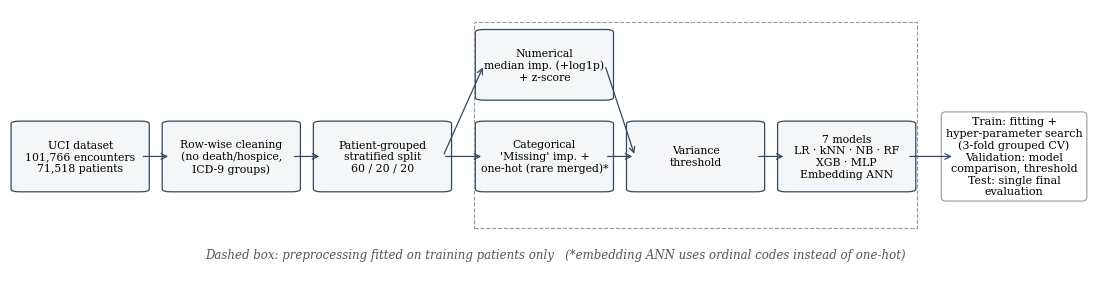

In [14]:
fig, ax = plt.subplots(figsize=(14, 3.4))
ax.axis("off")
W, H = 0.112, 0.2
boxes = {
    "data": (0.06, 0.55, "UCI dataset\n101,766 encounters\n71,518 patients"),
    "clean": (0.2, 0.55, "Row-wise cleaning\n(no death/hospice,\nICD-9 groups)"),
    "split": (0.34, 0.55, "Patient-grouped\nstratified split\n60 / 20 / 20"),
    "num": (0.49, 0.83, "Numerical\nmedian imp. (+log1p)\n+ z-score"),
    "cat": (0.49, 0.55, "Categorical\n'Missing' imp. +\none-hot (rare merged)*"),
    "vt": (0.63, 0.55, "Variance\nthreshold"),
    "clf": (0.77, 0.55, "7 models\nLR · kNN · NB · RF\nXGB · MLP\nEmbedding ANN"),
}
for x0, y0, t in boxes.values():
    ax.add_patch(plt.matplotlib.patches.FancyBboxPatch((x0 - W / 2, y0 - H / 2), W, H,
                 boxstyle="round,pad=0.008", fc="#F4F6F7", ec="#34495E", lw=0.9))
    ax.text(x0, y0, t, ha="center", va="center", fontsize=7.8)


def arrow(p, q):
    (x1, y1), (x2, y2) = boxes[p][:2], boxes[q][:2]
    ax.annotate("", xy=(x2 - W / 2, y2), xytext=(x1 + W / 2, y1),
                arrowprops=dict(arrowstyle="->", color="#34495E", lw=0.9))


for p, q in [("data", "clean"), ("clean", "split"), ("split", "num"), ("split", "cat"),
             ("num", "vt"), ("cat", "vt"), ("vt", "clf")]:
    arrow(p, q)
ax.text(0.925, 0.55, "Train: fitting +\nhyper-parameter search\n(3-fold grouped CV)\nValidation: model\ncomparison, threshold\nTest: single final\nevaluation",
        ha="center", va="center", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#999", lw=0.8))
ax.add_patch(plt.matplotlib.patches.Rectangle((0.425, 0.33), 0.41, 0.63, fill=False, ls="--", ec="#999", lw=0.8))
ax.text(0.5, 0.24, "Dashed box: preprocessing fitted on training patients only   "
        "(*embedding ANN uses ordinal codes instead of one-hot)",
        ha="center", fontsize=8.5, style="italic", color="#555")
ax.set_xlim(-0.005, 1.0)
ax.set_ylim(0.2, 1)
ax.annotate("", xy=(0.87, 0.55), xytext=(0.77 + W / 2, 0.55), arrowprops=dict(arrowstyle="->", color="#34495E", lw=0.9))
save_fig("fig3_pipeline")

## 6. Modeller ve hiperparametre seçimi
Hiperparametreler **eğitim seti içinde hasta bazlı 3-katlı çapraz doğrulama** ile seçiliyor: her aday 3 kez (her seferinde eğitim hastalarının 2/3'üyle) eğitilip kalan 1/3 üzerinde **PR-AUC (average precision)** ile ölçülüyor ve ortalaması alınıyor. Validation seti bu aşamada hiç kullanılmıyor; sadece eşik seçimi ve modellerin karşılaştırılması için ayrılıyor.

- Klasik modeller için geniş aralıklardan **rastgele arama** (ParameterSampler) yapılıyor.
- MLP için 5 mimari × 3 L2 cezasının **tamamı** deneniyor (YSA mimari denemesi).
- Overfitting'i görmek için her fold'da eğitim kısmının 10.000 kayıtlık alt örneğindeki skor da hesaplanıyor; train − CV farkı "gap" olarak raporlanıyor.
- Ana modellerde sınıf ağırlığı veya SMOTE kullanılmadı; dengesizlik eşik seçimiyle ele alındı (karşılaştırma: Bölüm 9).

In [15]:
def get_models():
    # (model, arama uzayı, rastgele aday sayısı; None = ızgaranın tamamı)
    return {
        "LR": (LogisticRegression(max_iter=3000, random_state=SEED),
               {"C": loguniform(1e-3, 10)}, 10),
        "kNN": (KNeighborsClassifier(n_jobs=-1),
                {"n_neighbors": randint(15, 301), "weights": ["uniform", "distance"]}, 8),
        "NB": (GaussianNB(),
               {"var_smoothing": loguniform(1e-9, 1e-1)}, 8),
        "RF": (RandomForestClassifier(n_jobs=-1, random_state=SEED),
               {"n_estimators": randint(200, 601), "max_depth": [8, 12, 16, 20, 30, None],
                "min_samples_leaf": randint(1, 51), "max_features": ["sqrt", 0.2, 0.4]}, 20),
        "XGB": (XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                              n_jobs=-1, random_state=SEED),
                {"n_estimators": randint(200, 1001), "max_depth": randint(2, 9),
                 "learning_rate": loguniform(0.01, 0.2), "min_child_weight": randint(1, 21),
                 "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
                 "reg_lambda": loguniform(0.1, 10)}, 25),
        "MLP": (MLPClassifier(activation="relu", solver="adam", learning_rate_init=1e-3, batch_size=256,
                              max_iter=200, early_stopping=True, validation_fraction=0.1,
                              n_iter_no_change=10, random_state=SEED),
                {"hidden_layer_sizes": [(32,), (128,), (64, 32), (256, 128), (256, 128, 64)],
                 "alpha": [1e-4, 1e-2, 1e-1]}, None),
    }


rng = np.random.default_rng(SEED)
sub = rng.choice(len(y_train), 20000, replace=False)
X_tr_sub, y_tr_sub = X_train.iloc[sub], y_train[sub]

inner_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
inner_splits = list(inner_cv.split(X_train, y_train, g_train))
for a, b in inner_splits:
    assert not set(g_train[a]) & set(g_train[b])


def cv_eval(fit_fn):
    # fit_fn(X, y, groups) -> predict_proba metodu olan, eğitilmiş model
    ap, auc, tr = [], [], []
    for a, b in inner_splits:
        m = fit_fn(X_train.iloc[a], y_train[a], g_train[a])
        p = m.predict_proba(X_train.iloc[b][FEATURES])[:, 1]
        ap.append(average_precision_score(y_train[b], p))
        auc.append(roc_auc_score(y_train[b], p))
        s_idx = a[:: max(1, len(a) // 10000)][:10000]
        tr.append(average_precision_score(y_train[s_idx], m.predict_proba(X_train.iloc[s_idx][FEATURES])[:, 1]))
    return {"cv_ap": np.mean(ap), "cv_ap_sd": np.std(ap), "cv_auc": np.mean(auc), "train_ap": np.mean(tr),
            "gap_ap": np.mean(tr) - np.mean(ap)}, m


def candidates(space, n_iter):
    if n_iter is None:
        return list(ParameterGrid(space))
    return list(ParameterSampler(space, n_iter=n_iter, random_state=SEED))


def tune(name, clf, space, n_iter):
    rows = []
    for params in candidates(space, n_iter):
        t0 = time.time()
        res, _ = cv_eval(lambda X, y, g: make_pipe(clone(clf).set_params(**params)).fit(X[FEATURES], y))
        res.update({"model": name, "params": params, "sec": round(time.time() - t0, 1)})
        rows.append(res)
    return pd.DataFrame(rows).sort_values("cv_ap", ascending=False).reset_index(drop=True)


def show(p):
    out = {}
    for k, v in p.items():
        if isinstance(v, (float, np.floating)):
            v = round(float(v), 4)
        elif isinstance(v, np.integer):
            v = int(v)
        out[k] = v
    return out


models = get_models()
tuning, best_params = {}, {}
for name, (clf, space, n_iter) in models.items():
    res = tune(name, clf, space, n_iter)
    tuning[name] = res
    best_params[name] = res.loc[0, "params"]
    print(f"{name:4s} | {len(res):2d} aday | CV AP = {res.loc[0, 'cv_ap']:.4f} ± {res.loc[0, 'cv_ap_sd']:.4f} "
          f"| CV AUC = {res.loc[0, 'cv_auc']:.4f} | train AP = {res.loc[0, 'train_ap']:.4f} "
          f"| {res['sec'].sum():.0f} sn\n       {show(res.loc[0, 'params'])}")
pd.concat(tuning.values()).assign(params=lambda d: d["params"].map(show)).to_csv("results/tuning_all.csv", index=False)

LR   | 10 aday | CV AP = 0.2126 ± 0.0034 | CV AUC = 0.6631 | train AP = 0.2262 | 136 sn
       {'C': 2.9154}
kNN  |  8 aday | CV AP = 0.1966 ± 0.0062 | CV AUC = 0.6406 | train AP = 1.0000 | 360 sn
       {'n_neighbors': 117, 'weights': 'distance'}
NB   |  8 aday | CV AP = 0.1944 ± 0.0057 | CV AUC = 0.6496 | train AP = 0.2040 | 70 sn
       {'var_smoothing': 0.0403}
RF   | 20 aday | CV AP = 0.2236 ± 0.0066 | CV AUC = 0.6657 | train AP = 0.4909 | 1379 sn
       {'max_depth': 12, 'max_features': 0.4, 'min_samples_leaf': 7, 'n_estimators': 463}
XGB  | 25 aday | CV AP = 0.2303 ± 0.0065 | CV AUC = 0.6731 | train AP = 0.4018 | 676 sn
       {'colsample_bytree': 0.9547, 'learning_rate': 0.0217, 'max_depth': 5, 'min_child_weight': 2, 'n_estimators': 589, 'reg_lambda': 0.2605, 'subsample': 0.8271}
MLP  | 15 aday | CV AP = 0.2169 ± 0.0067 | CV AUC = 0.6637 | train AP = 0.2599 | 559 sn
       {'alpha': 0.01, 'hidden_layer_sizes': (32,)}


### 6.1 YSA (MLP) mimari ve hiperparametre denemeleri
5 mimari (1–3 gizli katman, 32–256 nöron) × 3 L2 cezası = 15 konfigürasyon, her biri hasta bazlı 3-katlı CV ile değerlendirildi. Erken durdurma için her eğitimde eğitim kısmının %10'u içeride ayrılıyor.

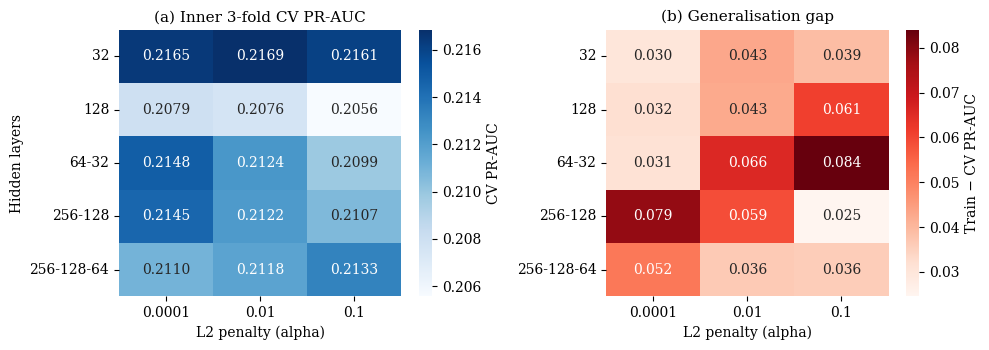

,architecture,alpha,train_ap,cv_ap,cv_ap_sd,cv_auc,gap_ap,sec
0,32,0.0100,0.2599,0.2169,0.0067,0.6637,0.0431,19.1
1,32,0.0001,0.2463,0.2165,0.0064,0.6650,0.0299,17.4
2,32,0.1000,0.2551,0.2161,0.0070,0.6650,0.0390,20.0
3,64-32,0.0001,0.2463,0.2148,0.0077,0.6643,0.0315,23.0
4,256-128,0.0001,0.2931,0.2145,0.0068,0.6598,0.0786,57.1
5,256-128-64,0.1000,0.2491,0.2133,0.0029,0.6666,0.0359,59.3
6,64-32,0.0100,0.2782,0.2124,0.0037,0.6610,0.0658,25.7
7,256-128,0.0100,0.2711,0.2122,0.0029,0.6595,0.0589,54.7
8,256-128-64,0.0100,0.2483,0.2118,0.0034,0.6661,0.0365,55.6
9,256-128-64,0.0001,0.2627,0.2110,0.0023,0.6643,0.0517,57.2


In [16]:
mlp = tuning["MLP"].copy()
mlp["architecture"] = mlp["params"].apply(lambda p: "-".join(map(str, p["hidden_layer_sizes"])))
mlp["alpha"] = mlp["params"].apply(lambda p: p["alpha"])
order = ["32", "128", "64-32", "256-128", "256-128-64"]
piv = mlp.pivot(index="architecture", columns="alpha", values="cv_ap").loc[order]
piv_gap = mlp.pivot(index="architecture", columns="alpha", values="gap_ap").loc[order]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sns.heatmap(piv, annot=True, fmt=".4f", cmap="Blues", ax=axes[0], cbar_kws={"label": "CV PR-AUC"})
axes[0].set_title("(a) Inner 3-fold CV PR-AUC")
axes[0].set_xlabel("L2 penalty (alpha)")
axes[0].set_ylabel("Hidden layers")
sns.heatmap(piv_gap, annot=True, fmt=".3f", cmap="Reds", ax=axes[1], cbar_kws={"label": "Train − CV PR-AUC"})
axes[1].set_title("(b) Generalisation gap")
axes[1].set_xlabel("L2 penalty (alpha)")
axes[1].set_ylabel("")
plt.tight_layout()
save_fig("fig4_mlp_grid")

mlp_table = mlp[["architecture", "alpha", "train_ap", "cv_ap", "cv_ap_sd", "cv_auc", "gap_ap", "sec"]]
mlp_table.to_csv("results/table_mlp_experiments.csv", index=False)
mlp_table.round(4)

### 6.2 Erken durdurma olmadan MLP: overfitting'in gözlenmesi
Seçilen mimari erken durdurma olmadan 60 epoch eğitilip her epoch'ta train ve validation kaybı kaydediliyor.

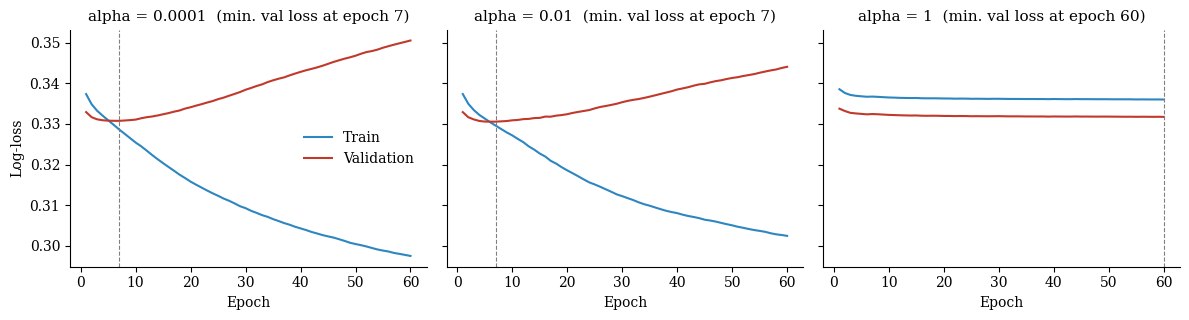

In [17]:
arch = best_params["MLP"]["hidden_layer_sizes"]
prep = make_pipe(None)[:-1]
Ztr = prep.fit_transform(X_train[FEATURES])
Zva = prep.transform(X_val[FEATURES])

curves = {}
for alpha in sorted({1e-4, best_params["MLP"]["alpha"], 1.0}):
    net = MLPClassifier(hidden_layer_sizes=arch, alpha=alpha, learning_rate_init=1e-3, batch_size=256,
                        random_state=SEED)
    tl, vl = [], []
    for ep in range(60):
        net.partial_fit(Ztr, y_train, classes=[0, 1])
        tl.append(log_loss(y_train, net.predict_proba(Ztr)))
        vl.append(log_loss(y_val, net.predict_proba(Zva)))
    curves[alpha] = (tl, vl)

fig, axes = plt.subplots(1, len(curves), figsize=(12, 3.3), sharey=True)
for ax, (alpha, (tl, vl)) in zip(np.atleast_1d(axes), curves.items()):
    ax.plot(range(1, 61), tl, label="Train", color="#2E86C1")
    ax.plot(range(1, 61), vl, label="Validation", color="#C0392B")
    ax.axvline(int(np.argmin(vl)) + 1, ls="--", color="grey", lw=0.8)
    ax.set_title(f"alpha = {alpha:g}  (min. val loss at epoch {int(np.argmin(vl)) + 1})")
    ax.set_xlabel("Epoch")
np.atleast_1d(axes)[0].set_ylabel("Log-loss")
np.atleast_1d(axes)[0].legend(frameon=False)
plt.tight_layout()
save_fig("fig5_mlp_learning_curves")

### 6.3 İkinci YSA: kategorik değişkenler için embedding katmanlı Keras ağı
MLP'de 37 kategorik değişken one-hot ile ~180 seyrek sütuna açılıyor. Burada her kategorik değişken bir **embedding katmanından** geçiyor (her kategori öğrenilen küçük bir vektörle temsil ediliyor), sayısal değişkenlerle birleştirilip yoğun (Dense) katmanlara veriliyor.
- Ön işleme yine sadece eğitim verisinde fit ediliyor (sayısal: medyan + log1p + z-skor; kategorik: OrdinalEncoder, nadir kategoriler birleşik, bilinmeyen kategori 0 indeksine düşüyor).
- Erken durdurma için eğitim hastalarının %10'u **hasta bazında** içeride ayrılıyor.
- Denenen mimariler: 3 farklı gizli katman yapısı × 2 dropout oranı; diğer modeller gibi hasta bazlı 3-katlı CV ile değerlendirilip en iyisi tüm eğitim setiyle yeniden eğitiliyor.

In [18]:
class EmbeddingANN:
    def __init__(self, hidden=(128, 64), dropout=0.2, lr=1e-3, batch_size=512, max_epochs=100,
                 patience=8, emb_max=10, seed=SEED):
        self.hidden, self.dropout, self.lr = hidden, dropout, lr
        self.batch_size, self.max_epochs, self.patience = batch_size, max_epochs, patience
        self.emb_max, self.seed = emb_max, seed

    def _transform(self, X):
        Xn = self.num_.transform(X[NUM_PLAIN + SKEWED]).astype("float32")
        Xc = (self.cat_.transform(X[CAT_COLS]) + 1).astype("int32")   # 0 = görülmemiş kategori
        return {"num": Xn, "cat": Xc}

    def _build(self, n_num):
        keras.utils.set_random_seed(self.seed)
        num_in = keras.Input(shape=(n_num,), name="num")
        cat_in = keras.Input(shape=(len(CAT_COLS),), dtype="int32", name="cat")
        parts = [num_in]
        for i, card in enumerate(self.cards_):
            dim = int(min(self.emb_max, (card + 1) // 2))
            col = layers.Lambda(lambda t, i=i: t[:, i])(cat_in)
            parts.append(layers.Embedding(card, dim)(col))
        x = layers.Concatenate()(parts)
        for h in self.hidden:
            x = layers.Dense(h, activation="relu")(x)
            x = layers.Dropout(self.dropout)(x)
        out = layers.Dense(1, activation="sigmoid")(x)
        model = keras.Model([num_in, cat_in], out)
        model.compile(optimizer=keras.optimizers.Adam(self.lr), loss="binary_crossentropy",
                      metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
        return model

    def fit(self, X, y, groups):
        a, b = next(GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=self.seed).split(X, y, groups))
        self.num_ = ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_PLAIN),
            ("skew", Pipeline([("imp", SimpleImputer(strategy="median")),
                               ("log", FunctionTransformer(np.log1p)), ("sc", StandardScaler())]), SKEWED)])
        self.cat_ = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                              ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                     min_frequency=50))])
        self.num_.fit(X.iloc[a][NUM_PLAIN + SKEWED])     # sadece eğitim kısmı
        self.cat_.fit(X.iloc[a][CAT_COLS])
        tr, va = self._transform(X.iloc[a]), self._transform(X.iloc[b])
        self.cards_ = [int(tr["cat"][:, i].max()) + 1 for i in range(len(CAT_COLS))]
        self.model_ = self._build(tr["num"].shape[1])
        es = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=self.patience,
                                           restore_best_weights=True)
        self.history_ = self.model_.fit(tr, np.asarray(y)[a], validation_data=(va, np.asarray(y)[b]),
                                        epochs=self.max_epochs, batch_size=self.batch_size,
                                        callbacks=[es], verbose=0).history
        return self

    def predict_proba(self, X):
        p = self.model_.predict(self._transform(X), batch_size=4096, verbose=0).ravel()
        return np.column_stack([1 - p, p])


ann2_grid = {"hidden": [(64,), (128, 64), (256, 128, 64)], "dropout": [0.1, 0.3]}
ann2_rows = []
for params in ParameterGrid(ann2_grid):
    t0 = time.time()
    res, m_last = cv_eval(lambda X, y, g: EmbeddingANN(**params).fit(X, y, g))
    res.update({"architecture": "-".join(map(str, params["hidden"])), "dropout": params["dropout"],
                "params": m_last.model_.count_params(), "sec": round(time.time() - t0, 1)})
    ann2_rows.append(res)
    print(res["architecture"], res["dropout"], f"CV AP = {res['cv_ap']:.4f}")
ann2_res = pd.DataFrame(ann2_rows)[["architecture", "dropout", "params", "train_ap", "cv_ap", "cv_ap_sd",
                                    "cv_auc", "gap_ap", "sec"]]
ann2_res = ann2_res.sort_values("cv_ap", ascending=False).reset_index(drop=True)
ann2_res.to_csv("results/table_ann2_experiments.csv", index=False)
best_ann2 = {"hidden": tuple(int(v) for v in ann2_res.loc[0, "architecture"].split("-")),
             "dropout": float(ann2_res.loc[0, "dropout"])}
print("Seçilen:", best_ann2)
ann2_final = EmbeddingANN(**best_ann2).fit(X_train[FEATURES], y_train, g_train)   # tüm eğitim seti
ann2_res.round(4)

64 0.1 CV AP = 0.2171


128-64 0.1 CV AP = 0.2153


256-128-64 0.1 CV AP = 0.2120


64 0.3 CV AP = 0.2176


128-64 0.3 CV AP = 0.2165


256-128-64 0.3 CV AP = 0.2153
Seçilen: {'hidden': (64,), 'dropout': 0.3}


,architecture,dropout,params,train_ap,cv_ap,cv_ap_sd,cv_auc,gap_ap,sec
0,64,0.3,9366,0.2327,0.2176,0.0079,0.6657,0.0150,74.1
1,64,0.1,9366,0.2624,0.2171,0.0077,0.6630,0.0453,89.3
2,128-64,0.3,25878,0.2543,0.2165,0.0044,0.6645,0.0378,88.2
3,256-128-64,0.3,75286,0.2494,0.2153,0.0077,0.6630,0.0341,93.4
4,128-64,0.1,25878,0.2464,0.2153,0.0058,0.6632,0.0311,76.0
5,256-128-64,0.1,75286,0.2427,0.2120,0.0101,0.6596,0.0307,80.6


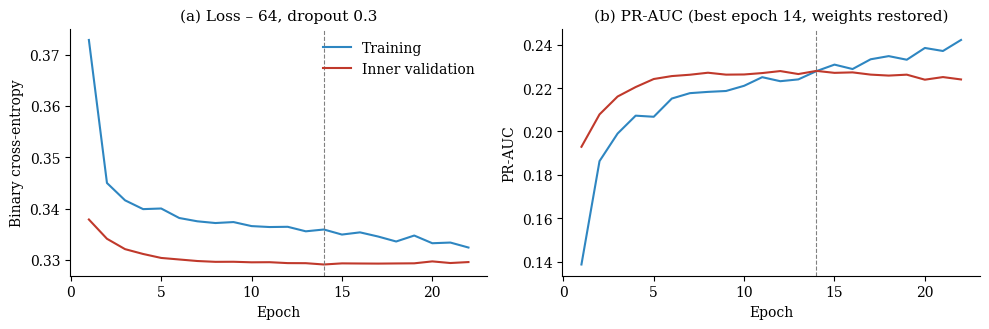

In [19]:
h = ann2_final.history_
ep = np.arange(1, len(h["loss"]) + 1)
best_ep = int(np.argmax(h["val_pr_auc"])) + 1
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(ep, h["loss"], color="#2E86C1", label="Training")
axes[0].plot(ep, h["val_loss"], color="#C0392B", label="Inner validation")
axes[0].set_ylabel("Binary cross-entropy")
axes[1].plot(ep, h["pr_auc"], color="#2E86C1", label="Training")
axes[1].plot(ep, h["val_pr_auc"], color="#C0392B", label="Inner validation")
axes[1].set_ylabel("PR-AUC")
for ax in axes:
    ax.axvline(best_ep, ls="--", color="grey", lw=0.8)
    ax.set_xlabel("Epoch")
axes[0].legend(frameon=False)
axes[0].set_title(f"(a) Loss – {ann2_res.loc[0, 'architecture']}, dropout {best_ann2['dropout']}")
axes[1].set_title(f"(b) PR-AUC (best epoch {best_ep}, weights restored)")
plt.tight_layout()
save_fig("fig13_ann2_training")

## 7. Seçilen modeller: validation sonuçları, eşik seçimi ve overfitting
Seçilen konfigürasyonlar tüm eğitim setiyle eğitiliyor. Validation seti burada ilk kez kullanılıyor: modeller karşılaştırılıyor ve her modelin eşiği validation'da F1'i maksimize eden olasılık değeri olarak belirleniyor; bu eşik test setine olduğu gibi uygulanıyor.

In [20]:
def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = np.nanargmax(f1[:-1])
    return float(thr[i])


def scores(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p), "Accuracy": accuracy_score(y, pred),
            "Balanced Acc": balanced_accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred)}


final, thresholds, val_rows = {}, {}, []
for name, (clf, _, _) in models.items():
    pipe = make_pipe(clone(clf).set_params(**best_params[name])).fit(X_train[FEATURES], y_train)
    final[name] = pipe
    p_va = pipe.predict_proba(X_val[FEATURES])[:, 1]
    thresholds[name] = best_threshold(y_val, p_va)
    r = scores(y_val, p_va, thresholds[name])
    r["Train PR-AUC"] = average_precision_score(y_tr_sub, pipe.predict_proba(X_tr_sub[FEATURES])[:, 1])
    r["Gap"] = r["Train PR-AUC"] - r["PR-AUC"]
    r["Threshold"] = thresholds[name]
    r["Model"] = NAMES[name]
    val_rows.append(r)

# Keras ağı: 6.3'te tüm eğitim setiyle eğitilen model
m = ann2_final
final["ANN2"] = m
p_va = m.predict_proba(X_val[FEATURES])[:, 1]
thresholds["ANN2"] = best_threshold(y_val, p_va)
r = scores(y_val, p_va, thresholds["ANN2"])
r["Train PR-AUC"] = average_precision_score(y_tr_sub, m.predict_proba(X_tr_sub[FEATURES])[:, 1])
r["Gap"] = r["Train PR-AUC"] - r["PR-AUC"]
r["Threshold"] = thresholds["ANN2"]
r["Model"] = NAMES["ANN2"]
val_rows.append(r)

dummy = DummyClassifier(strategy="prior").fit(X_train[FEATURES], y_train)
val_table = pd.DataFrame(val_rows).set_index("Model")
val_table.to_csv("results/table_validation.csv")
val_table.round(4)

,ROC-AUC,PR-AUC,Brier,Accuracy,Balanced Acc,Precision,Recall,F1,Train PR-AUC,Gap,Threshold
Model,,,,,,,,,,,
Logistic Regression,0.6669,0.2040,0.0954,0.7192,0.6204,0.1969,0.4932,0.2814,0.2215,0.0175,0.1267
k-NN,0.6459,0.1951,0.0960,0.6980,0.6003,0.1786,0.4745,0.2595,1.0000,0.8049,0.1287
Gaussian NB,0.6512,0.1880,0.1508,0.6531,0.6082,0.1714,0.5505,0.2614,0.1962,0.0082,0.1033
Random Forest,0.6795,0.2330,0.0939,0.7548,0.6181,0.2123,0.4422,0.2869,0.4380,0.2050,0.1407
XGBoost,0.6824,0.2379,0.0936,0.7376,0.6268,0.2086,0.4841,0.2915,0.3471,0.1092,0.1334
MLP (ANN),0.6606,0.2085,0.0957,0.7549,0.6072,0.2052,0.4171,0.2751,0.3116,0.1031,0.1535
Embedding ANN (Keras),0.6768,0.2192,0.0945,0.7238,0.6247,0.2012,0.4973,0.2865,0.2409,0.0216,0.1356


### 7.1 Kararlılık kontrolü: hasta bazlı 5-katlı çapraz doğrulama
Sonuçların tek bir validation bölünmesine bağlı olmadığını görmek için seçilen konfigürasyonlar train+validation verisi üzerinde **hasta bazlı, katmanlı 5-katlı CV** ile tekrar değerlendiriliyor. Her fold'da pipeline baştan fit ediliyor. Test seti burada da kullanılmıyor. Hiperparametreler bu verinin bir kısmı (eğitim seti) üzerinde seçildiği için bu tahmin hafif iyimser olabilir.

In [21]:
X_dev = pd.concat([X_train, X_val])
y_dev = np.concatenate([y_train, y_val])
g_dev = np.concatenate([g_train, g_val])

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for fold, (a, b) in enumerate(cv.split(X_dev, y_dev, g_dev), start=1):
    assert not set(g_dev[a]) & set(g_dev[b])
    for name, (clf, _, _) in models.items():
        pipe = make_pipe(clone(clf).set_params(**best_params[name])).fit(X_dev[FEATURES].iloc[a], y_dev[a])
        p = pipe.predict_proba(X_dev[FEATURES].iloc[b])[:, 1]
        cv_rows.append({"fold": fold, "model": name, "ROC-AUC": roc_auc_score(y_dev[b], p),
                        "PR-AUC": average_precision_score(y_dev[b], p)})
    p = EmbeddingANN(**best_ann2).fit(X_dev[FEATURES].iloc[a], y_dev[a], g_dev[a]).predict_proba(X_dev[FEATURES].iloc[b])[:, 1]
    cv_rows.append({"fold": fold, "model": "ANN2", "ROC-AUC": roc_auc_score(y_dev[b], p),
                    "PR-AUC": average_precision_score(y_dev[b], p)})
    print(f"fold {fold} tamam")
cvdf = pd.DataFrame(cv_rows)
cvdf.to_csv("results/cv_grouped_5fold.csv", index=False)

cv_sum = cvdf.groupby("model")[["ROC-AUC", "PR-AUC"]].agg(["mean", "std"])
cv_sum.index = [NAMES[i] for i in cv_sum.index]
cv_sum.to_csv("results/table_cv_summary.csv")
cv_sum.round(4)

fold 1 tamam


fold 2 tamam


fold 3 tamam


fold 4 tamam


fold 5 tamam


ROC-AUC          PR-AUC        
                         mean     std    mean     std
Embedding ANN (Keras)  0.6726  0.0117  0.2230  0.0130
Logistic Regression    0.6652  0.0117  0.2108  0.0107
MLP (ANN)              0.6639  0.0159  0.2130  0.0150
Gaussian NB            0.6501  0.0136  0.1935  0.0148
Random Forest          0.6726  0.0125  0.2332  0.0108
XGBoost                0.6782  0.0129  0.2368  0.0097
k-NN                   0.6431  0.0082  0.1965  0.0113

In [22]:
order_m = list(models) + ["ANN2"]
auc_mat = cvdf.pivot(index="fold", columns="model", values="ROC-AUC")[order_m]
ap_mat = cvdf.pivot(index="fold", columns="model", values="PR-AUC")[order_m]
for lab, mat in [("ROC-AUC", auc_mat), ("PR-AUC", ap_mat)]:
    fr = stats.friedmanchisquare(*[mat[c] for c in mat.columns])
    print(f"{lab}: Friedman chi2 = {fr.statistic:.2f}, p = {fr.pvalue:.4g}")
    print("  ortalama sıra:", mat.rank(axis=1, ascending=False).mean().sort_values().round(2).to_dict())
    print("  her fold'daki en iyi model:", mat.idxmax(axis=1).value_counts().to_dict())

ROC-AUC: Friedman chi2 = 27.94, p = 9.632e-05
  ortalama sıra: {'XGB': 1.0, 'ANN2': 2.4, 'RF': 2.6, 'LR': 4.6, 'MLP': 4.6, 'NB': 6.0, 'kNN': 6.8}
  her fold'daki en iyi model: {'XGB': 5}
PR-AUC: Friedman chi2 = 29.14, p = 5.716e-05
  ortalama sıra: {'XGB': 1.0, 'RF': 2.0, 'ANN2': 3.0, 'MLP': 4.4, 'LR': 4.6, 'kNN': 6.2, 'NB': 6.8}
  her fold'daki en iyi model: {'XGB': 5}


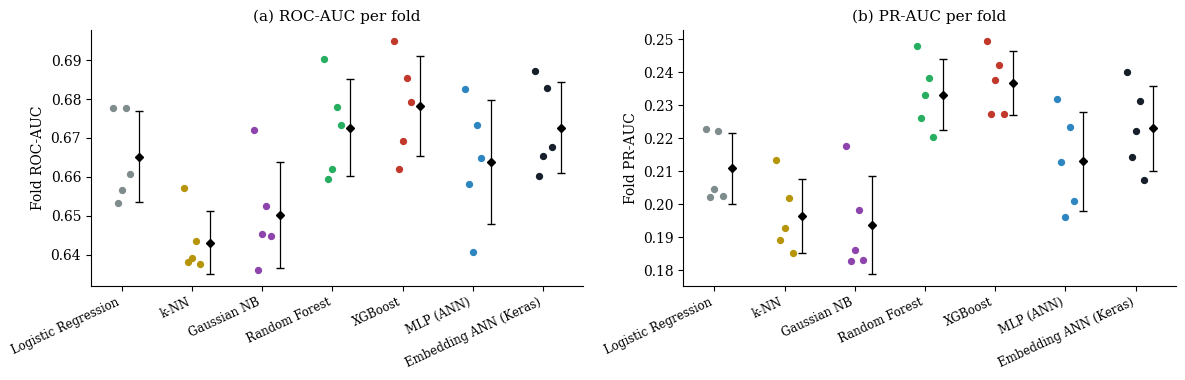

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, (lab, mat) in zip(axes, [("ROC-AUC", auc_mat), ("PR-AUC", ap_mat)]):
    for i, m in enumerate(order_m):
        ax.scatter(np.full(5, i) + np.linspace(-0.12, 0.12, 5), mat[m], color=COLORS[m], s=18, zorder=3)
        ax.errorbar(i + 0.25, mat[m].mean(), yerr=mat[m].std(), fmt="D", color="black", ms=4, capsize=3, lw=0.9)
    ax.set_xticks(range(len(order_m)))
    ax.set_xticklabels([NAMES[m] for m in order_m], rotation=25, ha="right", fontsize=8.5)
    ax.set_ylabel(f"Fold {lab}")
axes[0].set_title("(a) ROC-AUC per fold")
axes[1].set_title("(b) PR-AUC per fold")
plt.tight_layout()
save_fig("fig12_grouped_cv")

## 8. Test seti: tek seferlik nihai değerlendirme
Güven aralıkları **hasta bazlı bootstrap** ile (hastalar yeniden örneklenir) hesaplanıyor, çünkü aynı hastanın yatışları birbirinden bağımsız değil.

In [24]:
probs = {n: p.predict_proba(X_test[FEATURES])[:, 1] for n, p in final.items()}
probs_dummy = dummy.predict_proba(X_test[FEATURES])[:, 1]

test_rows = []
for n in final:
    r = scores(y_test, probs[n], thresholds[n])
    r["Model"] = NAMES[n]
    test_rows.append(r)
r = scores(y_test, probs_dummy, 0.5)
r["Model"] = "Majority baseline"
test_rows.append(r)
test_table = pd.DataFrame(test_rows).set_index("Model")

# hasta bazlı bootstrap
uniq_pat, inv = np.unique(g_test, return_inverse=True)
rows_of = pd.Series(np.arange(len(g_test))).groupby(inv).apply(np.array).values
B = 1000
boot = {n: {"auc": [], "ap": []} for n in final}
diff_auc = {n: [] for n in final}
rng = np.random.default_rng(SEED)
best_by_val = max(final, key=lambda n: val_table.loc[NAMES[n], "PR-AUC"])
for b in range(B):
    pick = rng.integers(0, len(uniq_pat), len(uniq_pat))
    idx = np.concatenate(rows_of[pick])
    yb = y_test[idx]
    for n in final:
        boot[n]["auc"].append(roc_auc_score(yb, probs[n][idx]))
        boot[n]["ap"].append(average_precision_score(yb, probs[n][idx]))
    for n in final:
        diff_auc[n].append(boot[best_by_val]["auc"][-1] - boot[n]["auc"][-1])

for n in final:
    lo, hi = np.percentile(boot[n]["auc"], [2.5, 97.5])
    test_table.loc[NAMES[n], "AUC CI"] = f"[{lo:.3f}, {hi:.3f}]"
    lo, hi = np.percentile(boot[n]["ap"], [2.5, 97.5])
    test_table.loc[NAMES[n], "PR-AUC CI"] = f"[{lo:.3f}, {hi:.3f}]"
test_table.to_csv("results/table_test.csv")
test_table.round(4)

,ROC-AUC,PR-AUC,Brier,Accuracy,Balanced Acc,Precision,Recall,F1,AUC CI,PR-AUC CI
Model,,,,,,,,,,
Logistic Regression,0.6585,0.2075,0.0987,0.7020,0.6143,0.1943,0.5002,0.2799,"[0.645, 0.672]","[0.191, 0.225]"
k-NN,0.6397,0.1975,0.0993,0.6880,0.5974,0.1807,0.4795,0.2624,"[0.625, 0.652]","[0.177, 0.217]"
Gaussian NB,0.6442,0.1907,0.1566,0.6388,0.6029,0.1721,0.5563,0.2629,"[0.630, 0.658]","[0.174, 0.209]"
Random Forest,0.6657,0.2259,0.0977,0.7401,0.6154,0.2107,0.4532,0.2876,"[0.652, 0.679]","[0.205, 0.247]"
XGBoost,0.6695,0.2358,0.0971,0.7248,0.6227,0.2079,0.4899,0.2919,"[0.656, 0.682]","[0.214, 0.258]"
MLP (ANN),0.6470,0.2102,0.0993,0.7452,0.5996,0.2029,0.4101,0.2715,"[0.633, 0.660]","[0.191, 0.229]"
Embedding ANN (Keras),0.6622,0.2170,0.0982,0.7069,0.6169,0.1974,0.4998,0.2831,"[0.648, 0.676]","[0.197, 0.237]"
Majority baseline,0.5000,0.1158,0.1024,0.8842,0.5000,0.0000,0.0000,0.0000,NaN,NaN


In [25]:
print("Validation'a göre seçilen birincil model:", NAMES[best_by_val])
cmp = []
for n in final:
    if n == best_by_val:
        continue
    d = np.array(diff_auc[n])
    p_two = 2 * (min(int((d <= 0).sum()), int((d >= 0).sum())) + 1) / (B + 1)  # finite-bootstrap adjustment
    cmp.append((NAMES[n], d.mean(), *np.percentile(d, [2.5, 97.5]), min(p_two, 1.0)))
cmp = pd.DataFrame(cmp, columns=["Compared with", "ΔAUC (best − model)", "CI low", "CI high", "bootstrap p"])
cmp.to_csv("results/table_auc_differences.csv", index=False)
cmp.round(4)

Validation'a göre seçilen birincil model: XGBoost


,Compared with,ΔAUC (best − model),CI low,CI high,bootstrap p
0,Logistic Regression,0.0109,0.0058,0.0164,0.002
1,k-NN,0.0298,0.0215,0.0393,0.002
2,Gaussian NB,0.0252,0.0176,0.0328,0.002
3,Random Forest,0.0038,-0.0009,0.0084,0.122
4,MLP (ANN),0.0224,0.0150,0.0299,0.002
5,Embedding ANN (Keras),0.0072,0.0031,0.0116,0.008


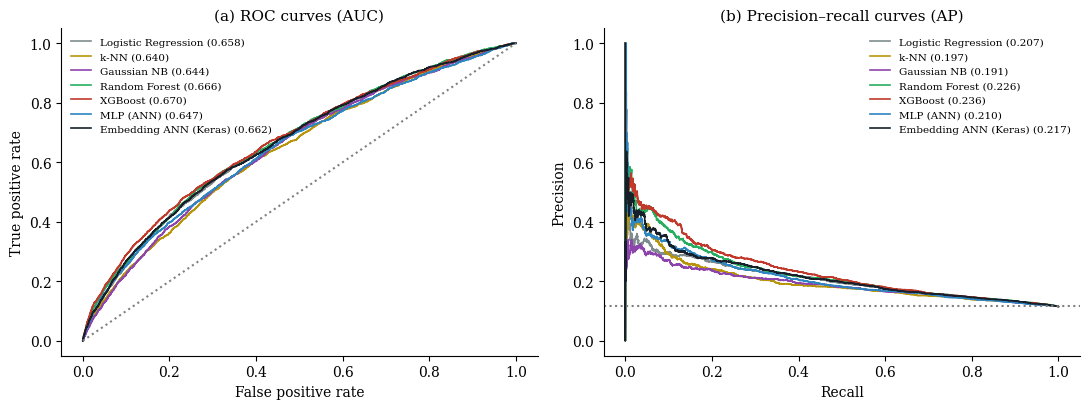

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for n in final:
    fpr, tpr, _ = roc_curve(y_test, probs[n])
    axes[0].plot(fpr, tpr, color=COLORS[n], lw=1.2, label=f"{NAMES[n]} ({roc_auc_score(y_test, probs[n]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, probs[n])
    axes[1].plot(rc, pr, color=COLORS[n], lw=1.2,
                 label=f"{NAMES[n]} ({average_precision_score(y_test, probs[n]):.3f})")
axes[0].plot([0, 1], [0, 1], ls=":", color="grey")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("(a) ROC curves (AUC)")
axes[1].axhline(y_test.mean(), ls=":", color="grey")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("(b) Precision–recall curves (AP)")
for ax in axes:
    ax.legend(fontsize=7.5, frameon=False)
plt.tight_layout()
save_fig("fig6_roc_pr")

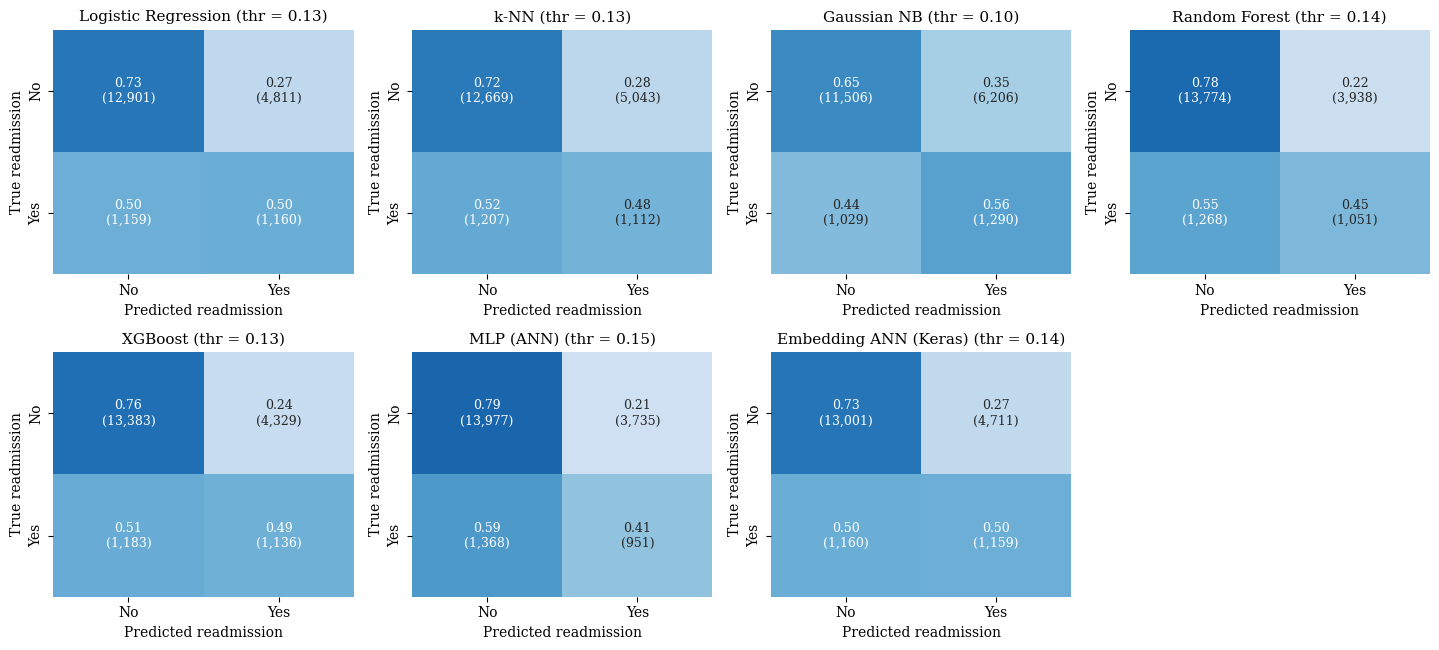

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(14.5, 6.6))
for ax in axes.ravel()[len(final):]:
    ax.axis("off")
for ax, n in zip(axes.ravel(), final):
    pred = (probs[n] >= thresholds[n]).astype(int)
    cm = confusion_matrix(y_test, pred)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f"{cmn[i, j]:.2f}\n({cm[i, j]:,})" for j in range(2)] for i in range(2)]),
                fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], annot_kws={"fontsize": 9})
    ax.set_title(f"{NAMES[n]} (thr = {thresholds[n]:.2f})")
    ax.set_xlabel("Predicted readmission")
    ax.set_ylabel("True readmission")
plt.tight_layout()
save_fig("fig7_confusion_matrices")

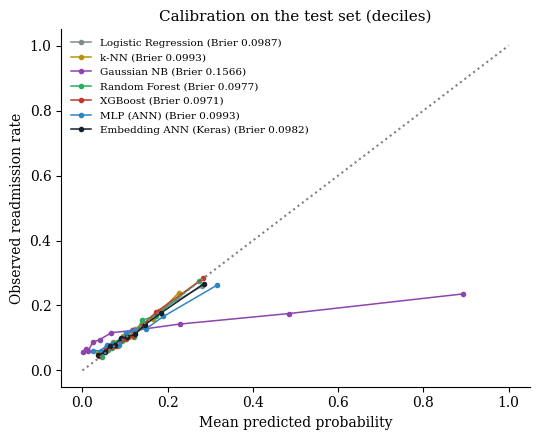

In [28]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for n in final:
    fr, mp = calibration_curve(y_test, probs[n], n_bins=10, strategy="quantile")
    ax.plot(mp, fr, marker="o", ms=3, lw=1.1, color=COLORS[n],
            label=f"{NAMES[n]} (Brier {brier_score_loss(y_test, probs[n]):.4f})")
ax.plot([0, 1], [0, 1], ls=":", color="grey")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed readmission rate")
ax.set_title("Calibration on the test set (deciles)")
ax.legend(fontsize=7.5, frameon=False)
plt.tight_layout()
save_fig("fig8_calibration")

## 9. Dengesiz veri deneyi: sınıf ağırlığı ve SMOTE
Ana analizde sınıf dengesizliği yalnızca eşik seçimiyle ele alındı. Burada LR, RF ve XGBoost için iki yaygın yöntem karşılaştırılıyor:
- **Sınıf ağırlığı:** pozitif sınıfın hatası daha ağır cezalandırılıyor (LR/RF: `class_weight="balanced"`, XGBoost: `scale_pos_weight` = negatif/pozitif oranı, train'den).
- **SMOTE:** sentetik pozitif örnek üretimi. `imblearn` Pipeline içinde olduğu için **sadece fit sırasında ve sadece train verisine** uygulanıyor; validation ve test hiç değişmiyor.

Her varyantın eşiği yine validation'da seçiliyor. Ayrıca varsayılan 0,5 eşiğindeki F1 de raporlanıyor.

In [29]:
pos_w = (y_train == 0).sum() / (y_train == 1).sum()
imb_rows = []
for n in ["LR", "RF", "XGB"]:
    base = clone(models[n][0]).set_params(**best_params[n])
    cw = {"scale_pos_weight": pos_w} if n == "XGB" else {"class_weight": "balanced"}
    variants = {
        "No correction": make_pipe(clone(base)),
        "Class weights": make_pipe(clone(base).set_params(**cw)),
        "SMOTE": ImbPipeline([("prep", make_preprocessor()), ("vt", VarianceThreshold(0.0)),
                              ("smote", SMOTE(random_state=SEED)), ("clf", clone(base))]),
    }
    for v, pipe in variants.items():
        pipe.fit(X_train[FEATURES], y_train)          # SMOTE yalnızca burada, train üzerinde çalışır
        p_va = pipe.predict_proba(X_val[FEATURES])[:, 1]
        thr = best_threshold(y_val, p_va)
        p_te = pipe.predict_proba(X_test[FEATURES])[:, 1]
        r = scores(y_test, p_te, thr)
        r.update({"Model": NAMES[n], "Strategy": v, "Threshold": thr,
                  "F1 @ 0.5": f1_score(y_test, (p_te >= 0.5).astype(int)),
                  "Mean predicted risk": p_te.mean()})
        imb_rows.append(r)
    print(n, "tamam")
imb = pd.DataFrame(imb_rows)[["Model", "Strategy", "ROC-AUC", "PR-AUC", "Brier", "Mean predicted risk",
                              "Threshold", "F1", "Recall", "Precision", "F1 @ 0.5"]]
imb.to_csv("results/table_imbalance.csv", index=False)
print("Gerçek pozitif oran (test):", round(y_test.mean(), 4))
imb.round(4)

LR tamam
RF tamam
XGB tamam
Gerçek pozitif oran (test): 0.1158


,Model,Strategy,ROC-AUC,PR-AUC,Brier,Mean predicted risk,Threshold,F1,Recall,Precision,F1 @ 0.5
0,Logistic Regression,No correction,0.6585,0.2075,0.0987,0.1152,0.1267,0.2799,0.5002,0.1943,0.0119
1,Logistic Regression,Class weights,0.6587,0.2052,0.2284,0.4657,0.5233,0.2790,0.5201,0.1906,0.2739
2,Logistic Regression,SMOTE,0.6471,0.1971,0.2277,0.4567,0.5421,0.2720,0.4804,0.1897,0.2689
3,Random Forest,No correction,0.6657,0.2259,0.0977,0.1157,0.1407,0.2876,0.4532,0.2107,0.0286
4,Random Forest,Class weights,0.6632,0.2214,0.1882,0.4091,0.5064,0.2801,0.4079,0.2133,0.2786
5,Random Forest,SMOTE,0.6516,0.2186,0.1138,0.2318,0.2782,0.2759,0.4437,0.2002,0.1642
6,XGBoost,No correction,0.6695,0.2358,0.0971,0.1148,0.1334,0.2919,0.4899,0.2079,0.0350
7,XGBoost,Class weights,0.6672,0.2282,0.2142,0.4468,0.5319,0.2889,0.4847,0.2058,0.2776
8,XGBoost,SMOTE,0.6588,0.2219,0.0984,0.1337,0.1693,0.2836,0.4131,0.2159,0.0349


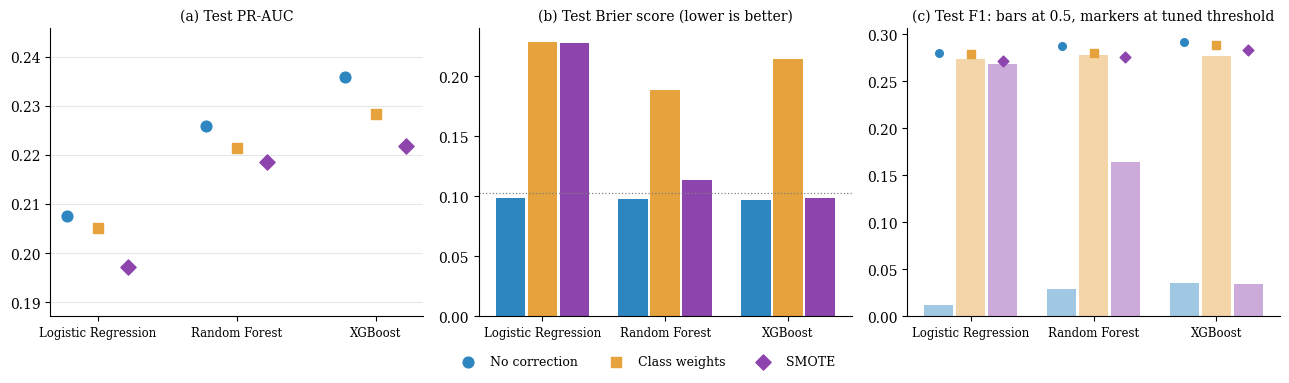

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
strat = ["No correction", "Class weights", "SMOTE"]
st_col = {"No correction": "#2E86C1", "Class weights": "#E6A23C", "SMOTE": "#8E44AD"}
st_mk = {"No correction": "o", "Class weights": "s", "SMOTE": "D"}
mods = ["Logistic Regression", "Random Forest", "XGBoost"]
x = np.arange(len(mods))
for k, sname in enumerate(strat):
    sub_i = imb[imb.Strategy == sname].set_index("Model").loc[mods]
    # PR-AUC için nokta grafiği (eksen sıfırdan başlamıyor), Brier ve F1 için sıfırdan başlayan çubuklar
    axes[0].scatter(x + (k - 1) * 0.22, sub_i["PR-AUC"], s=60, color=st_col[sname], marker=st_mk[sname],
                    zorder=3, label=sname)
    axes[1].bar(x + (k - 1) * 0.26, sub_i["Brier"], 0.24, color=st_col[sname])
    axes[2].bar(x + (k - 1) * 0.26, sub_i["F1 @ 0.5"], 0.24, color=st_col[sname], alpha=0.45)
    axes[2].scatter(x + (k - 1) * 0.26, sub_i["F1"], color=st_col[sname], marker=st_mk[sname], s=30, zorder=3)
for ax, t in zip(axes, ["(a) Test PR-AUC", "(b) Test Brier score (lower is better)",
                        "(c) Test F1: bars at 0.5, markers at tuned threshold"]):
    ax.set_xticks(x)
    ax.set_xticklabels(mods, fontsize=8.5)
    ax.set_title(t, fontsize=10)
pr = imb["PR-AUC"]
axes[0].set_ylim(pr.min() - 0.01, pr.max() + 0.01)
axes[0].grid(axis="y", alpha=0.3)
axes[1].axhline(brier_score_loss(y_test, probs_dummy), ls=":", color="grey", lw=0.9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.07))
plt.tight_layout()
save_fig("fig14_imbalance")

## 10. Veri sızıntısı deneyi: hasta bazlı bölme yerine rastgele bölme yapılsaydı?
Literatürde sık yapılan hata, yatışları hastaya bakmadan rastgele bölmek. Bu durumda aynı hastanın yatışları hem train'de hem test'te olabiliyor. Aynı modelleri aynı hiperparametrelerle **rastgele (yatış bazlı) 60/20/20** bölmeyle eğitip test performansını karşılaştırıyorum. Not: bu deneydeki test seti farklı olduğu için asıl sonuç tablosuna dahil değil.

In [31]:
idx = np.arange(len(y_all))
n_dev, n_te = train_test_split(idx, test_size=0.2, stratify=y_all, random_state=SEED)
n_tr, n_va = train_test_split(n_dev, test_size=0.25, stratify=y_all[n_dev], random_state=SEED)
overlap = np.isin(groups_all[n_te], groups_all[n_tr]).mean()
print(f"Rastgele bölmede test yatışlarının {overlap * 100:.1f}%'inin hastası train'de de var.")

leak_rows = []
for n in ["LR", "RF", "XGB", "MLP"]:
    clf = clone(models[n][0]).set_params(**best_params[n])
    p = make_pipe(clf).fit(X_all.iloc[n_tr][FEATURES], y_all[n_tr]).predict_proba(X_all.iloc[n_te][FEATURES])[:, 1]
    leak_rows.append({"Model": NAMES[n], "Split": "Encounter-level (naive)",
                      "ROC-AUC": roc_auc_score(y_all[n_te], p), "PR-AUC": average_precision_score(y_all[n_te], p)})
    leak_rows.append({"Model": NAMES[n], "Split": "Patient-level (ours)",
                      "ROC-AUC": roc_auc_score(y_test, probs[n]), "PR-AUC": average_precision_score(y_test, probs[n])})
leak = pd.DataFrame(leak_rows)
leak.to_csv("results/table_leakage.csv", index=False)
leak.pivot(index="Model", columns="Split", values=["ROC-AUC", "PR-AUC"]).round(4)

Rastgele bölmede test yatışlarının 35.7%'inin hastası train'de de var.


ROC-AUC                       \
Split               Encounter-level (naive) Patient-level (ours)   
Model                                                              
Logistic Regression                  0.6703               0.6585   
MLP (ANN)                            0.6718               0.6470   
Random Forest                        0.6714               0.6657   
XGBoost                              0.6805               0.6695   

                                     PR-AUC                       
Split               Encounter-level (naive) Patient-level (ours)  
Model                                                             
Logistic Regression                  0.2179               0.2075  
MLP (ANN)                            0.2233               0.2102  
Random Forest                        0.2293               0.2259  
XGBoost                              0.2335               0.2358

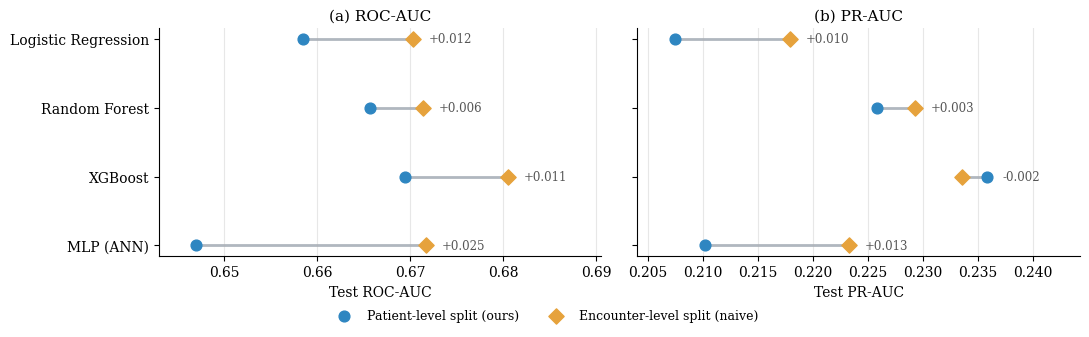

In [32]:
# çubuk yerine nokta grafiği: eksen sıfırdan başlamadığı için çubuk boyu farkı abartırdı
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
order_l = ["Logistic Regression", "Random Forest", "XGBoost", "MLP (ANN)"]
for ax, met in zip(axes, ["ROC-AUC", "PR-AUC"]):
    pv = leak.pivot(index="Model", columns="Split", values=met).loc[order_l]
    yy = np.arange(len(pv))[::-1]
    a, b = pv["Patient-level (ours)"].values, pv["Encounter-level (naive)"].values
    lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
    span = hi - lo
    ax.hlines(yy, a, b, color="#B0B7BF", lw=2, zorder=1)
    ax.scatter(a, yy, s=60, color="#2E86C1", marker="o", zorder=3, label="Patient-level split (ours)")
    ax.scatter(b, yy, s=60, color="#E6A23C", marker="D", zorder=3, label="Encounter-level split (naive)")
    for yi, ai, bi in zip(yy, a, b):
        ax.text(max(ai, bi) + span * 0.05, yi, f"{bi - ai:+.3f}", va="center", fontsize=8.5, color="#555555")
    ax.set_xlim(lo - span * 0.12, hi + span * 0.3)
    ax.set_yticks(yy)
    ax.set_yticklabels(pv.index)
    ax.set_xlabel(f"Test {met}")
    ax.grid(axis="x", alpha=0.3)
axes[0].set_title("(a) ROC-AUC")
axes[1].set_title("(b) PR-AUC")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
save_fig("fig9_leakage_experiment")

## 11. Veri miktarının etkisi (öğrenme eğrisi)
Eğitim verisinin farklı oranlarıyla (hasta bazında alt örnekleme) LR, XGBoost ve MLP eğitilip validation PR-AUC ölçülüyor. YSA'nın veri büyüdükçe ağaç modelleriyle arasındaki farkı kapatıp kapatmadığını görmek için.

0.05 tamam
0.10 tamam
0.25 tamam
0.50 tamam
1.00 tamam


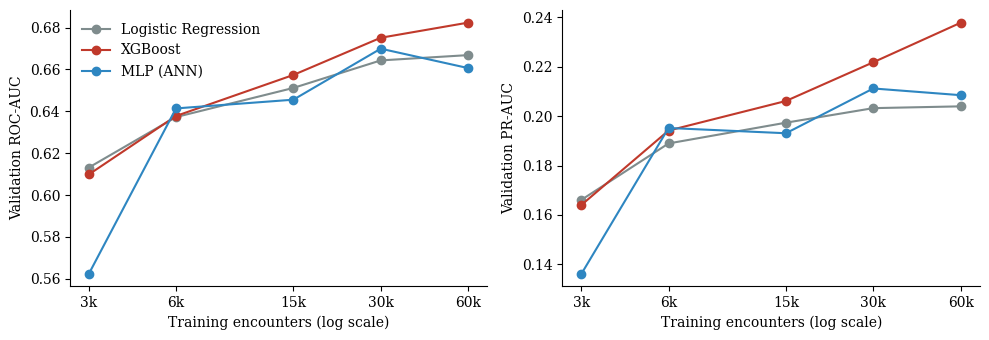

model,LR,MLP,XGB
n_train,,,
3006,0.1661,0.1362,0.1641
5967,0.1890,0.1952,0.1942
15029,0.1974,0.1931,0.2062
29888,0.2033,0.2112,0.2219
59616,0.2040,0.2085,0.2379


In [33]:
fracs = [0.05, 0.1, 0.25, 0.5, 1.0]
pats = np.unique(g_train)
rng = np.random.default_rng(SEED)
perm = rng.permutation(pats)
lc_rows = []
for f in fracs:
    keep = np.isin(g_train, perm[: int(len(perm) * f)])
    for n in ["LR", "XGB", "MLP"]:
        clf = clone(models[n][0]).set_params(**best_params[n])
        p = make_pipe(clf).fit(X_train[FEATURES].iloc[np.where(keep)[0]], y_train[keep]).predict_proba(X_val[FEATURES])[:, 1]
        lc_rows.append({"fraction": f, "n_train": int(keep.sum()), "model": n,
                        "val_ap": average_precision_score(y_val, p), "val_auc": roc_auc_score(y_val, p)})
    print(f"{f:.2f} tamam")
lc = pd.DataFrame(lc_rows)
lc.to_csv("results/table_learning_curve.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, met, lab in zip(axes, ["val_auc", "val_ap"], ["Validation ROC-AUC", "Validation PR-AUC"]):
    for n in ["LR", "XGB", "MLP"]:
        s = lc[lc.model == n]
        ax.plot(s["n_train"], s[met], marker="o", color=COLORS[n], label=NAMES[n])
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(sorted(lc["n_train"].unique()))
    ax.set_xticklabels([f"{v / 1000:.0f}k" for v in sorted(lc["n_train"].unique())])
    ax.set_xlabel("Training encounters (log scale)")
    ax.set_ylabel(lab)
axes[0].legend(frameon=False)
plt.tight_layout()
save_fig("fig10_training_size")
lc.pivot(index="n_train", columns="model", values="val_ap").round(4)

## 12. Değişken önemi (permutation importance)
En iyi scikit-learn modeli ve MLP için test setinden 10.000 kayıtlık sabit bir alt örnekte, ham değişken düzeyinde (one-hot sütunlar birlikte) PR-AUC düşüşü olarak hesaplanıyor.

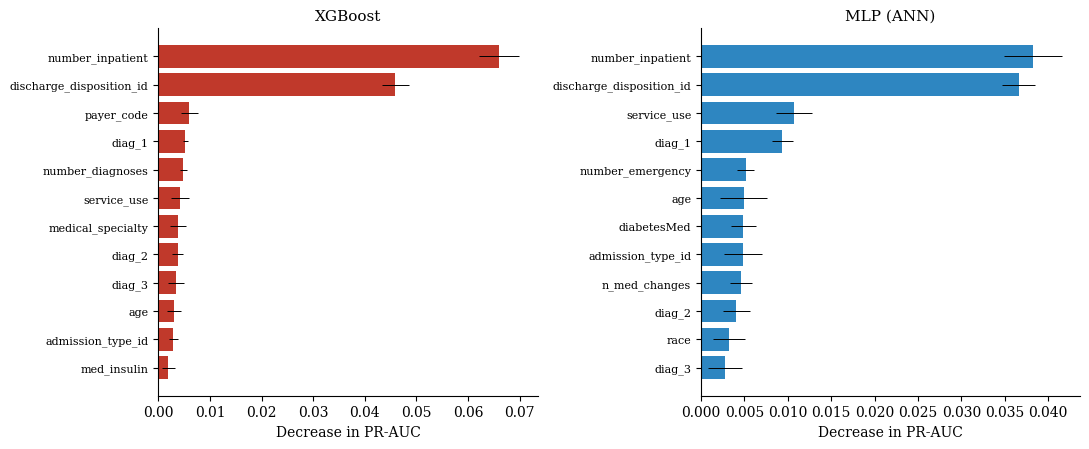

,mean,std
number_inpatient,0.0660,0.0039
discharge_disposition_id,0.0459,0.0027
payer_code,0.0060,0.0016
diag_1,0.0052,0.0005
number_diagnoses,0.0048,0.0007
service_use,0.0042,0.0017
medical_specialty,0.0038,0.0015
diag_2,0.0037,0.0011
diag_3,0.0034,0.0015
age,0.0030,0.0014


In [34]:
rs = np.random.default_rng(SEED).choice(len(y_test), 10000, replace=False)
imp = {}
best_sk = max(models, key=lambda n: val_table.loc[NAMES[n], "PR-AUC"])   # permutation_importance sklearn modeli istiyor
for n in dict.fromkeys([best_sk, "MLP"]):
    pi = permutation_importance(final[n], X_test[FEATURES].iloc[rs], y_test[rs], scoring="average_precision",
                                n_repeats=5, random_state=SEED, n_jobs=1)
    imp[n] = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=FEATURES)

fig, axes = plt.subplots(1, len(imp), figsize=(11, 4.6))
for ax, n in zip(np.atleast_1d(axes), imp):
    top = imp[n].sort_values("mean").tail(12)
    ax.barh(top.index, top["mean"], xerr=top["std"], color=COLORS[n], error_kw=dict(lw=0.7))
    ax.set_title(NAMES[n])
    ax.set_xlabel("Decrease in PR-AUC")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
save_fig("fig11_permutation_importance")
imp[best_sk].sort_values("mean", ascending=False).head(10).round(4)

## 13. Alt grup analizi
Klinik karar destek amacıyla kullanılacak bir modelin yaş, cinsiyet ve ırk gruplarında benzer çalışıp çalışmadığına bakılıyor (birincil model, validation eşiği).

In [35]:
n = best_by_val
pred = (probs[n] >= thresholds[n]).astype(int)
age_grp = pd.cut(X_test["age"], [0, 60, 80, 100], right=False, labels=["<60", "60–79", "80+"])
sub_rows = []
for col, ser in [("Age", age_grp), ("Gender", X_test["gender"]), ("Race", X_test["race"].fillna("Missing"))]:
    for g in ser.dropna().unique():
        m = (ser == g).values
        if m.sum() < 300 or y_test[m].sum() < 20:
            continue
        sub_rows.append({"Attribute": col, "Group": g, "n": int(m.sum()), "Readm. rate": y_test[m].mean(),
                         "ROC-AUC": roc_auc_score(y_test[m], probs[n][m]),
                         "Recall": recall_score(y_test[m], pred[m]),
                         "Precision": precision_score(y_test[m], pred[m], zero_division=0)})
subgroups = pd.DataFrame(sub_rows)
subgroups.to_csv("results/table_subgroups.csv", index=False)
subgroups.round(3)

,Attribute,Group,n,Readm. rate,ROC-AUC,Recall,Precision
0,Age,<60,6612,0.107,0.716,0.508,0.244
1,Age,60–79,9466,0.117,0.659,0.493,0.205
2,Age,80+,3953,0.126,0.591,0.457,0.174
3,Gender,Female,10898,0.117,0.668,0.502,0.206
4,Gender,Male,9133,0.114,0.671,0.474,0.210
5,Race,Caucasian,14880,0.115,0.671,0.491,0.207
6,Race,AfricanAmerican,3848,0.124,0.661,0.506,0.211
7,Race,Missing,449,0.080,0.600,0.250,0.108
8,Race,Hispanic,431,0.118,0.739,0.510,0.243


## 14. Çıktıların kaydedilmesi
Şekiller (600 dpi) ve tablolar `YSA_F26_ciktilar.zip` dosyasına kaydediliyor.

In [36]:
import shutil
os.makedirs("ciktilar", exist_ok=True)
shutil.copytree("figures", "ciktilar/figures", dirs_exist_ok=True)
shutil.copytree("results", "ciktilar/results", dirs_exist_ok=True)
shutil.make_archive("YSA_F26_ciktilar", "zip", "ciktilar")
try:
    from google.colab import files
    files.download("YSA_F26_ciktilar.zip")
except ImportError:
    pass